## **Project Members:**
**Muhammad Usama Umer**

**Muniba Manaal**

# Sea Animals Image Classification Using ResNet

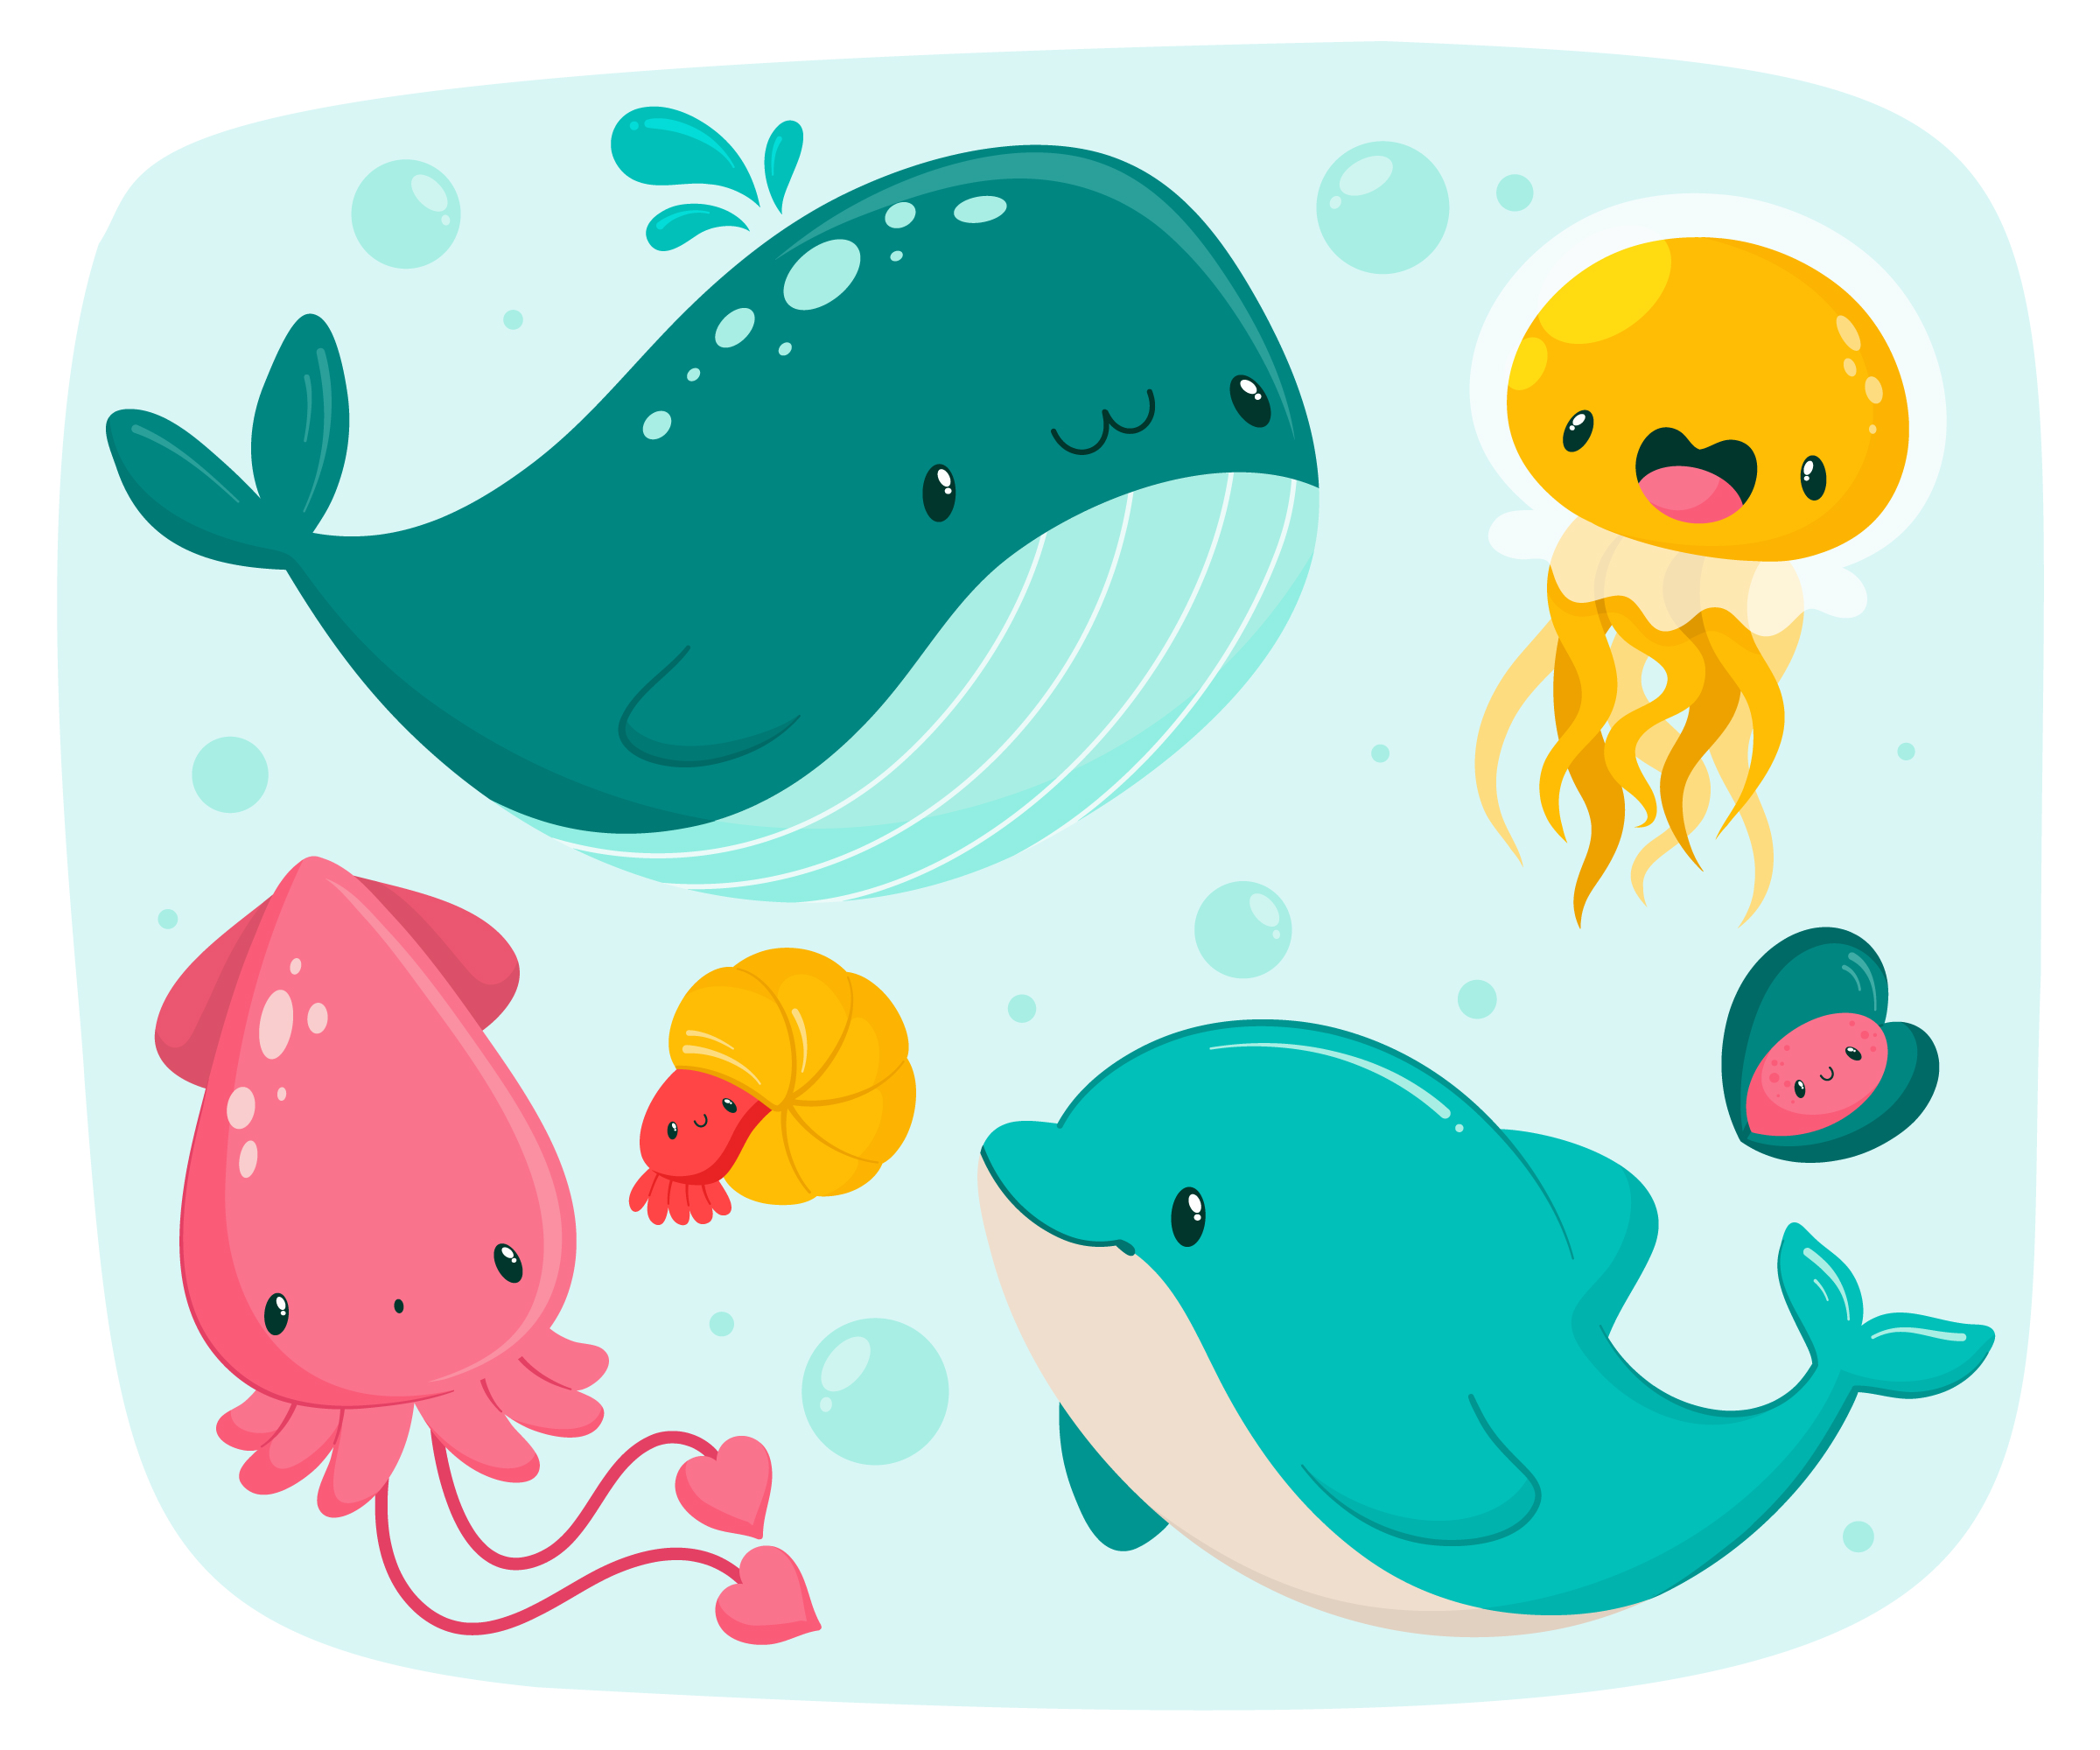

#### The dataset has 23 different Sea animal classes.

*   Clams

*   Corals

*   Crabs

*   Dolphin
*   Eel


*   Fish


*   Jelly Fish


*   Lobster

*   Nudibranchs

*   Octopus
*   Otter


*   Penguin

*   Puffers

*   Sea Rays

*   Sea Urchins

*   Seahorse
*   Seal


*   Sharks


*   Shrimp


*   Squid

*   Starfish
*   Turtle_Tortoise

*   Whale



In [2]:
!pip install kagglehub --quiet

In [3]:
import os
import numpy as np
import tensorflow as tf
from keras import Sequential
from keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator # Changed import location
from keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.applications import ResNet50V2
import kagglehub

In [4]:
# Download latest version of dataset using kagglehub
path = kagglehub.dataset_download("vencerlanz09/sea-animals-image-dataste")
print("Path to dataset files:", path)


Path to dataset files: /kaggle/input/sea-animals-image-dataste


In [5]:
# Check available classes
class_names = sorted(os.listdir(path))
print(f"Total Number of Classes: {len(class_names)}")
print("Class names:", class_names)

Total Number of Classes: 23
Class names: ['Clams', 'Corals', 'Crabs', 'Dolphin', 'Eel', 'Fish', 'Jelly Fish', 'Lobster', 'Nudibranchs', 'Octopus', 'Otter', 'Penguin', 'Puffers', 'Sea Rays', 'Sea Urchins', 'Seahorse', 'Seal', 'Sharks', 'Shrimp', 'Squid', 'Starfish', 'Turtle_Tortoise', 'Whale']


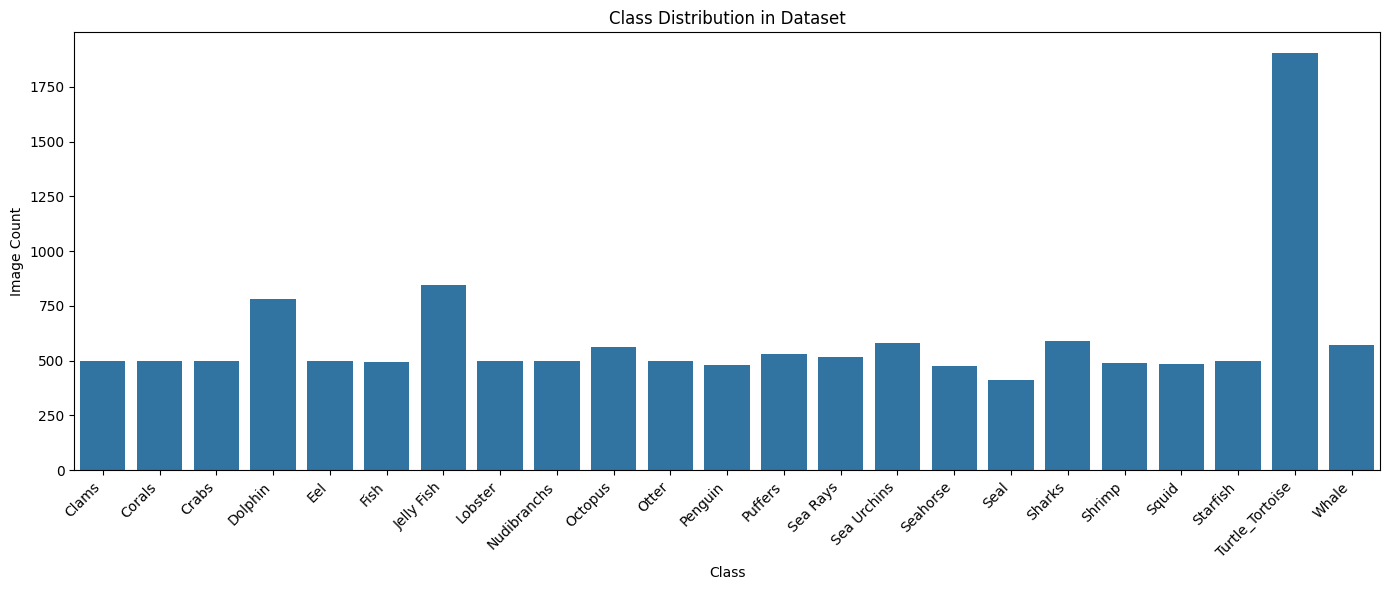

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Count the number of images per class
class_counts = {class_name: len(os.listdir(os.path.join(path, class_name))) for class_name in class_names}
df_counts = pd.DataFrame(list(class_counts.items()), columns=['Class', 'Image Count'])

# Plot
plt.figure(figsize=(14, 6))
sns.barplot(data=df_counts, x='Class', y='Image Count')
plt.xticks(rotation=45, ha='right')
plt.title("Class Distribution in Dataset")
plt.tight_layout()
plt.show()


In [9]:
IMG_SIZE = (256, 256)
BATCH_SIZE = 32

train_val_gen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=25,
    horizontal_flip=True,
    zoom_range=0.2,
    validation_split=0.1
)

train_ds = train_val_gen.flow_from_directory(
    path,
    target_size=IMG_SIZE,
    class_mode="sparse",
    batch_size=BATCH_SIZE,
    shuffle=True,
    subset='training'
)

valid_ds = train_val_gen.flow_from_directory(
    path,
    target_size=IMG_SIZE,
    class_mode="sparse",
    batch_size=BATCH_SIZE,
    shuffle=True,
    subset='validation'
)


Found 12350 images belonging to 23 classes.
Found 1361 images belonging to 23 classes.


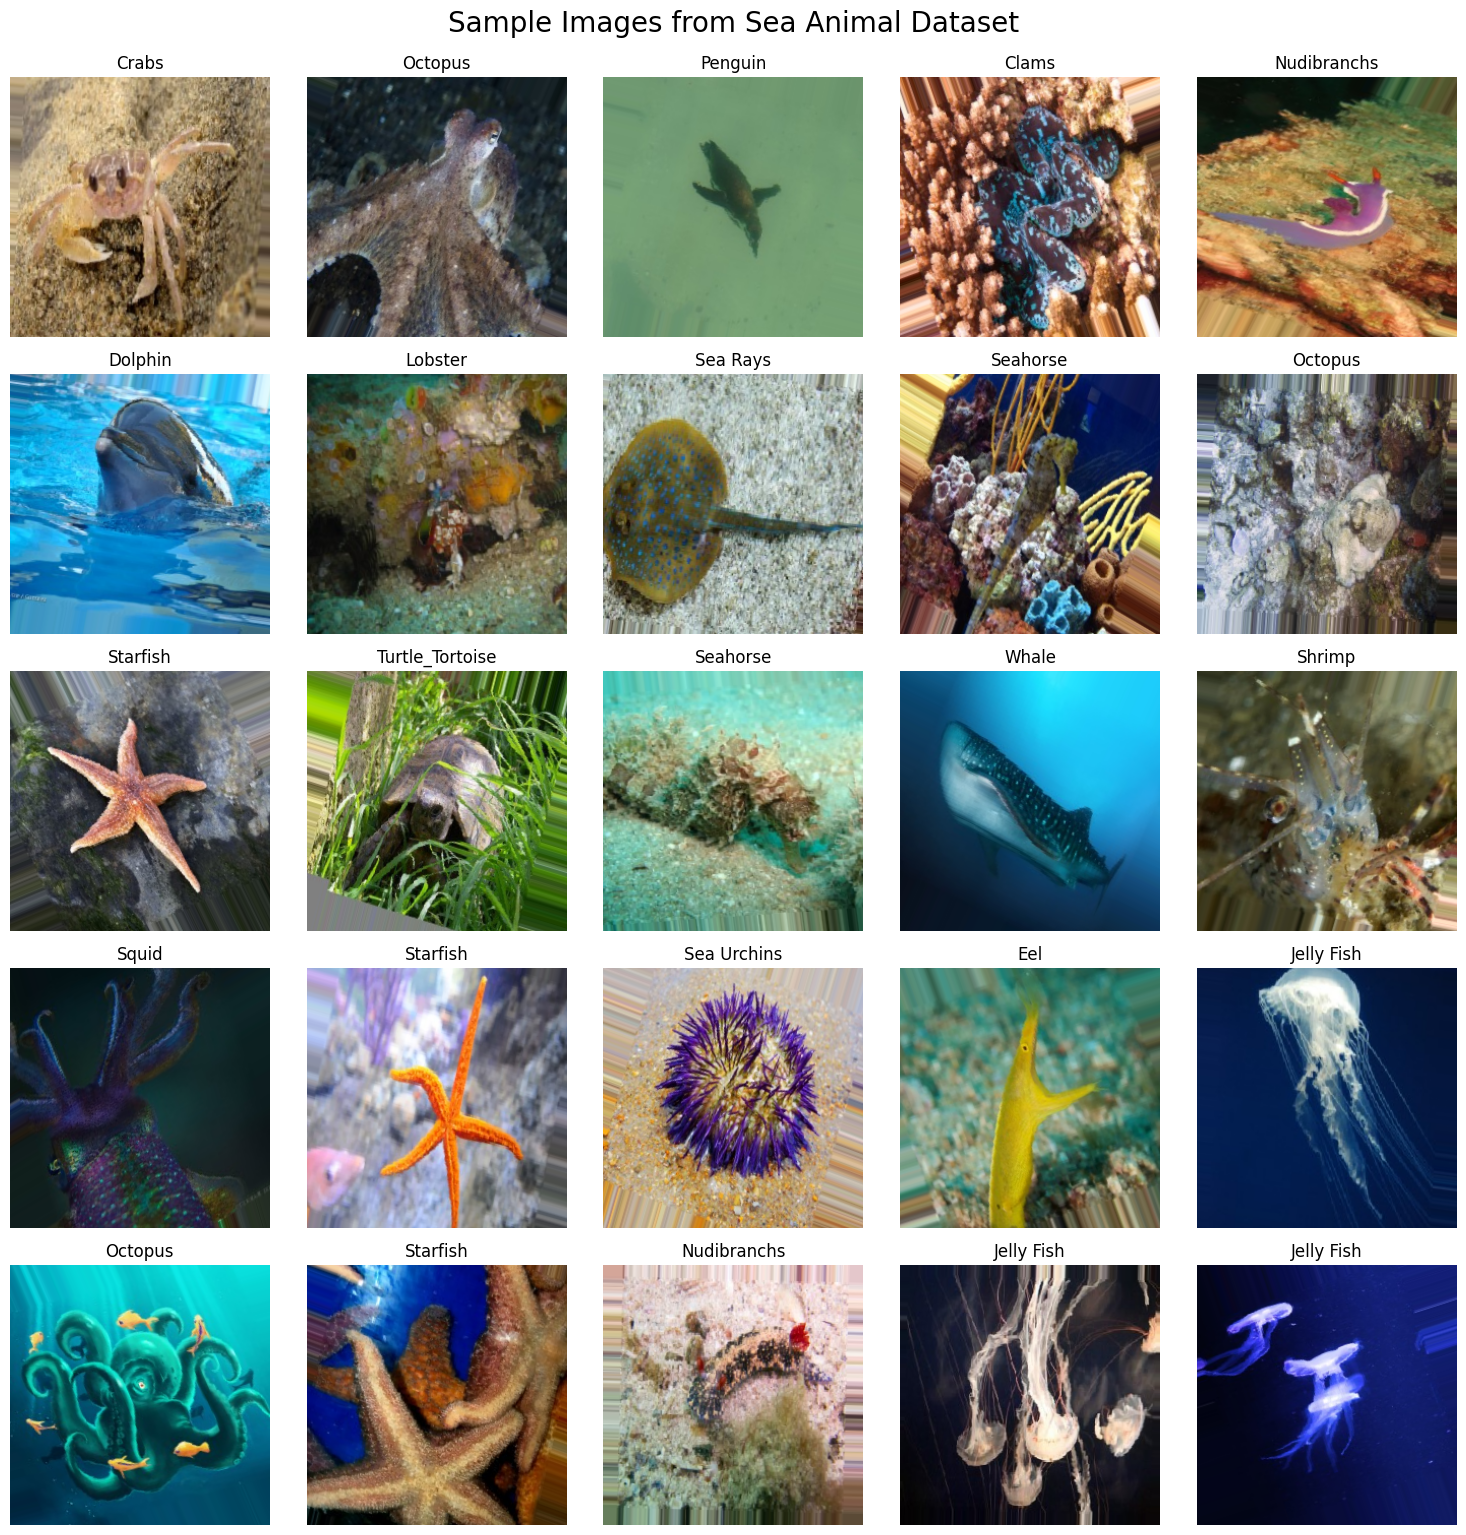

In [10]:
import matplotlib.pyplot as plt

# Get a batch of images and labels
images, labels = next(train_ds)

# Plot the first 25 images
plt.figure(figsize=(15, 15))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(images[i])
    plt.title(class_names[int(labels[i])])
    plt.axis('off')

plt.tight_layout()
plt.suptitle('Sample Images from Sea Animal Dataset', fontsize=20, y=1.02)
plt.show()


#### ImageDataGenerator is properly splitting the dataset:



*   90% training (12,350 images)
*   10% validation (1,361 images)




In [11]:
base_model = ResNet50V2(
    include_top=False,
    weights='imagenet',
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
)
base_model.trainable = False  # Freeze feature extractor

model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(len(class_names), activation='softmax')
], name="ResNet50V2")

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()


94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "ResNet50V2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)         │ (None, 8, 8, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 23)             │         5,911 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,095,255 (91.92 MB)

 Trainable params: 530,455 (2.02 MB)

 Non-trainable params: 23,564,800 (89.89 MB)

In [12]:

# =============================
# STEP 6: Train Model
# =============================
callbacks = [
    EarlyStopping(patience=5, restore_best_weights=True),
    ModelCheckpoint("ResNet50V2-best.h5", save_best_only=True)
]

history = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=35,
    callbacks=callbacks
)


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/35
386/386 ━━━━━━━━━━━━━━━━━━━━ 0s 684ms/step - accuracy: 0.5978 - loss: 1.4127

386/386 ━━━━━━━━━━━━━━━━━━━━ 325s 802ms/step - accuracy: 0.5980 - loss: 1.4119 - val_accuracy: 0.7818 - val_loss: 0.7051
Epoch 2/35
386/386 ━━━━━━━━━━━━━━━━━━━━ 0s 512ms/step - accuracy: 0.7648 - loss: 0.7733

386/386 ━━━━━━━━━━━━━━━━━━━━ 222s 567ms/step - accuracy: 0.7648 - loss: 0.7733 - val_accuracy: 0.8060 - val_loss: 0.6538
Epoch 3/35
386/386 ━━━━━━━━━━━━━━━━━━━━ 0s 518ms/step - accuracy: 0.7785 - loss: 0.7155

386/386 ━━━━━━━━━━━━━━━━━━━━ 242s 626ms/step - accuracy: 0.7785 - loss: 0.7154 - val_accuracy: 0.8163 - val_loss: 0.6140
Epoch 4/35
386/386 ━━━━━━━━━━━━━━━━━━━━ 223s 578ms/step - accuracy: 0.8082 - loss: 0.6189 - val_accuracy: 0.8009 - val_loss: 0.6416
Epoch 5/35
386/386 ━━━━━━━━━━━━━━━━━━━━ 218s 564ms/step - accuracy: 0.8210 - loss: 0.5667 - val_accuracy: 0.8009 - val_loss: 0.6202
Epoch 6/35
386/386 ━━━━━━━━━━━━━━━━━━━━ 216s 560ms/step - accuracy: 0.8277 - loss: 0.5407 - val_accuracy: 0.8112 - val_loss: 0.6210
Epoch 7/35
386/386 ━━━━━━━━━━━━━━━━━━━━ 212s 550ms/step - accuracy: 0.8341 - loss: 0.4964 - val_accuracy: 0.8112 - val_loss: 0.6561
Epoch 8/35
386/386 ━━━━━━━━━━━━━━━━━━━━ 212s 550ms/step - accuracy: 0.8345 - loss: 0.5113 - val_accuracy: 0.8097 - val_loss: 0.6296


In [13]:

# =============================
# STEP 7: Evaluate
# =============================
val_loss, val_acc = model.evaluate(valid_ds)
print(f"Validation Accuracy: {val_acc:.4f}")

43/43 ━━━━━━━━━━━━━━━━━━━━ 21s 493ms/step - accuracy: 0.8094 - loss: 0.6477
Validation Accuracy: 0.8134


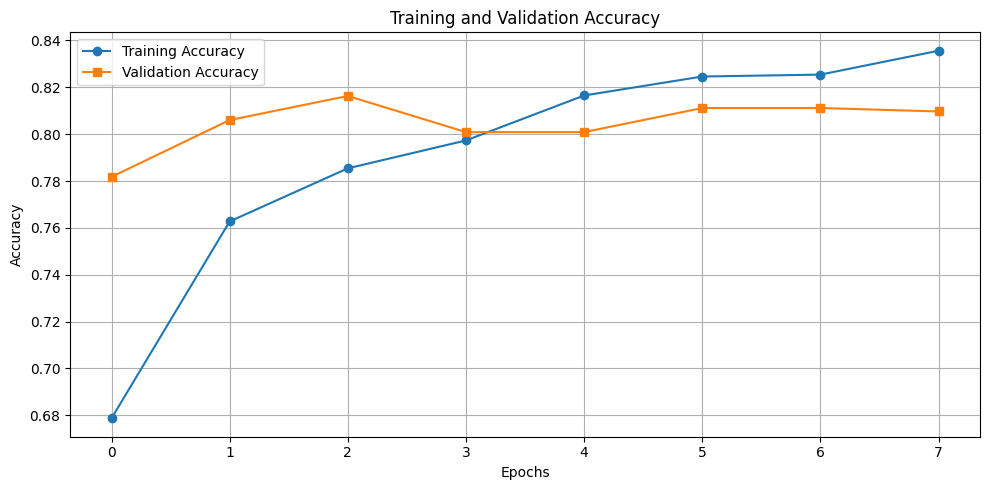

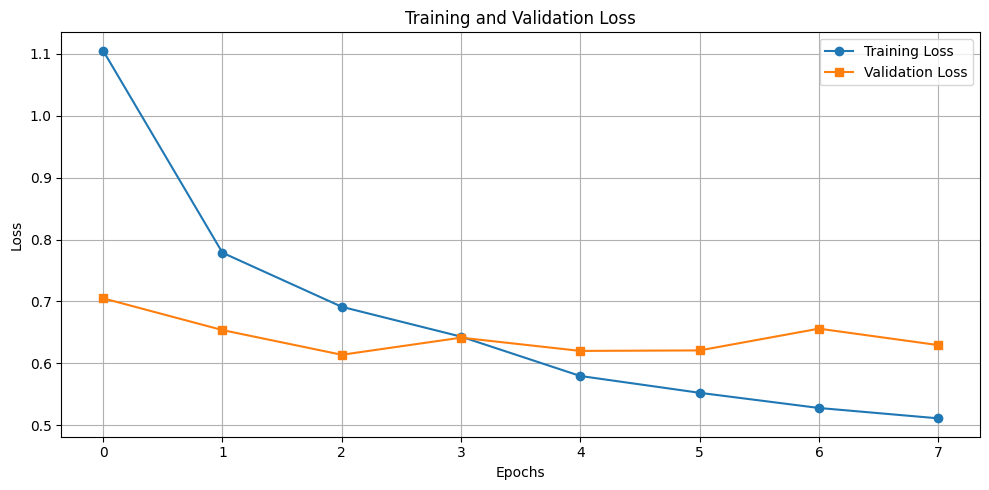

In [14]:
import matplotlib.pyplot as plt

# Plot Accuracy
plt.figure(figsize=(10, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy', marker='o')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', marker='s')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot Loss
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Training Loss', marker='o')
plt.plot(history.history['val_loss'], label='Validation Loss', marker='s')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [15]:
# Step 1: Create a new validation generator for evaluation (NO SHUFFLE)
valid_ds_eval = train_val_gen.flow_from_directory(
    path,
    target_size=IMG_SIZE,
    class_mode="sparse",
    batch_size=BATCH_SIZE,
    shuffle=False,
    subset='validation'
)

# Step 2: Get predicted class probabilities
y_pred_probs = model.predict(valid_ds_eval)

# Step 3: Convert to predicted class labels (one with highest probability)
y_pred_classes = np.argmax(y_pred_probs, axis=1)

# Step 4: Get true class labels (already in correct order due to shuffle=False)
y_true = valid_ds_eval.classes

# Step 5: Make sure your class names are in correct order
class_names = sorted(os.listdir(path))

# Step 6: Print classification report
from sklearn.metrics import classification_report
print("Classification Report:\n")
print(classification_report(y_true, y_pred_classes, target_names=class_names))


Found 1361 images belonging to 23 classes.
43/43 ━━━━━━━━━━━━━━━━━━━━ 27s 538ms/step
Classification Report:

                 precision    recall  f1-score   support

          Clams       0.56      0.71      0.62        49
         Corals       0.67      0.64      0.65        50
          Crabs       0.91      0.98      0.94        49
        Dolphin       0.97      0.92      0.95        78
            Eel       0.49      0.51      0.50        49
           Fish       0.68      0.69      0.69        49
     Jelly Fish       0.97      1.00      0.98        84
        Lobster       0.79      0.63      0.70        49
    Nudibranchs       0.77      0.60      0.67        50
        Octopus       0.56      0.71      0.62        56
          Otter       0.98      0.96      0.97        50
        Penguin       0.96      0.94      0.95        48
        Puffers       0.84      0.60      0.70        53
       Sea Rays       0.73      0.73      0.73        51
    Sea Urchins       1.00      0.9

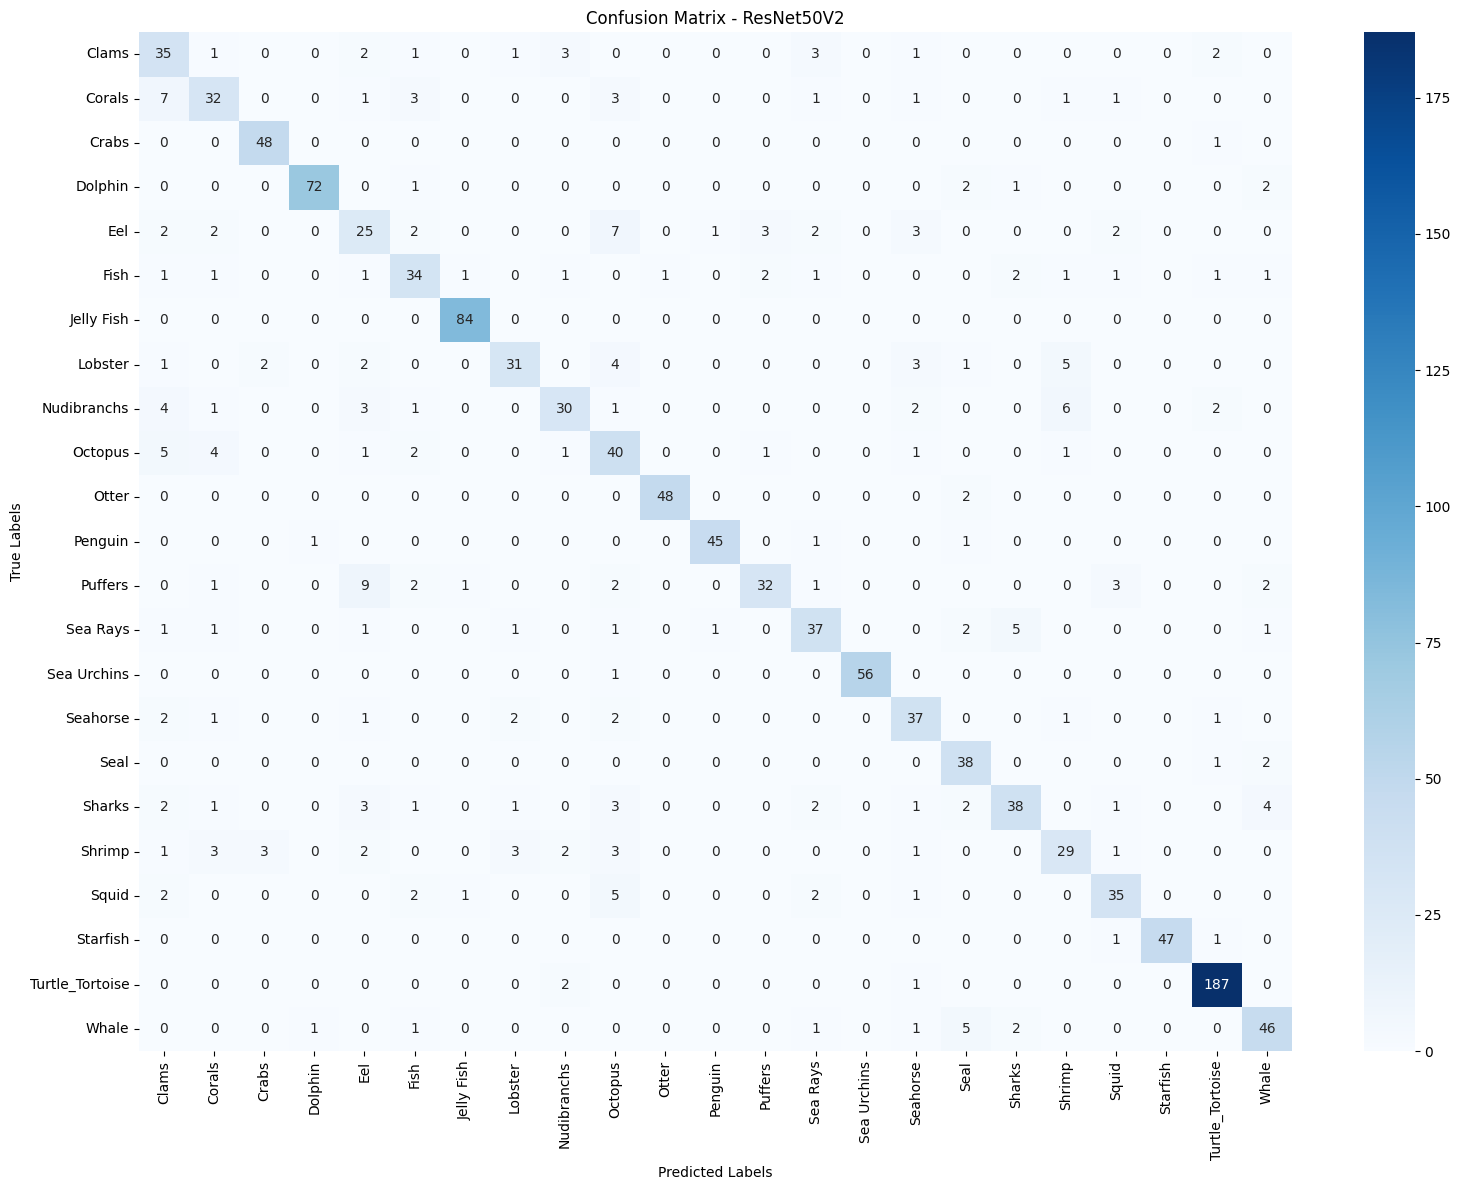

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred_classes)

# Plotting
plt.figure(figsize=(16, 12))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix - ResNet50V2')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:
# =============================
# STEP 8: Build Custom CNN for Comparison
# =============================
from keras.layers import Conv2D, MaxPooling2D, Flatten, BatchNormalization
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

print("="*50)
print("BUILDING CUSTOM CNN FOR COMPARISON")
print("="*50)

# Build Custom CNN Architecture
custom_cnn = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    BatchNormalization(),
    MaxPooling2D(2, 2),

    Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2, 2),

    Conv2D(128, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2, 2),

    Conv2D(256, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2, 2),

    GlobalAveragePooling2D(),
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(len(class_names), activation='softmax')
], name="Custom_CNN")

custom_cnn.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

print("\nCustom CNN Architecture:")
custom_cnn.summary()

# =============================
# STEP 9: Train Custom CNN
# =============================
print("\nTraining Custom CNN...")
callbacks_cnn = [
    EarlyStopping(patience=5, restore_best_weights=True),
    ModelCheckpoint("Custom_CNN-best.h5", save_best_only=True)
]

history_cnn = custom_cnn.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=35,
    callbacks=callbacks_cnn,
    verbose=1
)



BUILDING CUSTOM CNN FOR COMPARISON


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Custom CNN Architecture:


Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 254, 254, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 125, 125, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 60, 60, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 23)             │         5,911 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

...

386/386 ━━━━━━━━━━━━━━━━━━━━ 216s 561ms/step - accuracy: 0.5227 - loss: 1.5432 - val_accuracy: 0.5099 - val_loss: 1.6373
Epoch 23/35
386/386 ━━━━━━━━━━━━━━━━━━━━ 0s 501ms/step - accuracy: 0.5356 - loss: 1.4979

386/386 ━━━━━━━━━━━━━━━━━━━━ 214s 554ms/step - accuracy: 0.5356 - loss: 1.4980 - val_accuracy: 0.4938 - val_loss: 1.6366
Epoch 24/35
386/386 ━━━━━━━━━━━━━━━━━━━━ 209s 541ms/step - accuracy: 0.5353 - loss: 1.4789 - val_accuracy: 0.4269 - val_loss: 1.9802
Epoch 25/35
386/386 ━━━━━━━━━━━━━━━━━━━━ 210s 545ms/step - accuracy: 0.5580 - loss: 1.4138 - val_accuracy: 0.4585 - val_loss: 1.9585
Epoch 26/35
386/386 ━━━━━━━━━━━━━━━━━━━━ 212s 550ms/step - accuracy: 0.5580 - loss: 1.4252 - val_accuracy: 0.3740 - val_loss: 3.1006
Epoch 27/35
386/386 ━━━━━━━━━━━━━━━━━━━━ 0s 489ms/step - accuracy: 0.5704 - loss: 1.3856

386/386 ━━━━━━━━━━━━━━━━━━━━ 209s 541ms/step - accuracy: 0.5704 - loss: 1.3857 - val_accuracy: 0.5290 - val_loss: 1.5606
Epoch 28/35
386/386 ━━━━━━━━━━━━━━━━━━━━ 208s 540ms/step - accuracy: 0.5811 - loss: 1.3537 - val_accuracy: 0.5092 - val_loss: 1.6143
Epoch 29/35
386/386 ━━━━━━━━━━━━━━━━━━━━ 209s 541ms/step - accuracy: 0.5744 - loss: 1.3297 - val_accuracy: 0.5158 - val_loss: 1.5785
Epoch 30/35
386/386 ━━━━━━━━━━━━━━━━━━━━ 0s 489ms/step - accuracy: 0.5871 - loss: 1.3277

386/386 ━━━━━━━━━━━━━━━━━━━━ 209s 541ms/step - accuracy: 0.5871 - loss: 1.3277 - val_accuracy: 0.5452 - val_loss: 1.5232
Epoch 31/35
386/386 ━━━━━━━━━━━━━━━━━━━━ 209s 542ms/step - accuracy: 0.5985 - loss: 1.2923 - val_accuracy: 0.5165 - val_loss: 1.5674
Epoch 32/35
386/386 ━━━━━━━━━━━━━━━━━━━━ 0s 490ms/step - accuracy: 0.6012 - loss: 1.2694

386/386 ━━━━━━━━━━━━━━━━━━━━ 208s 539ms/step - accuracy: 0.6012 - loss: 1.2695 - val_accuracy: 0.5650 - val_loss: 1.4736
Epoch 33/35
386/386 ━━━━━━━━━━━━━━━━━━━━ 211s 545ms/step - accuracy: 0.6106 - loss: 1.2501 - val_accuracy: 0.5151 - val_loss: 1.5741
Epoch 34/35
386/386 ━━━━━━━━━━━━━━━━━━━━ 213s 552ms/step - accuracy: 0.6182 - loss: 1.2268 - val_accuracy: 0.5562 - val_loss: 1.4872
Epoch 35/35
386/386 ━━━━━━━━━━━━━━━━━━━━ 213s 551ms/step - accuracy: 0.6217 - loss: 1.2245 - val_accuracy: 0.5393 - val_loss: 1.5309


43/43 ━━━━━━━━━━━━━━━━━━━━ 21s 490ms/step - accuracy: 0.5739 - loss: 1.4635
Custom CNN Validation Accuracy: 0.5702
MODEL PERFORMANCE COMPARISON

Model Comparison Summary:
                         Model  Validation Accuracy  Validation Loss  Total Parameters  Trainable Parameters
ResNet50V2 (Transfer Learning)             0.813372          0.61646          24095255                530455
                    Custom CNN             0.570169          1.47186            659159                658199

🏆 BEST MODEL: ResNet50V2
🎯 Best Validation Accuracy: 0.8134


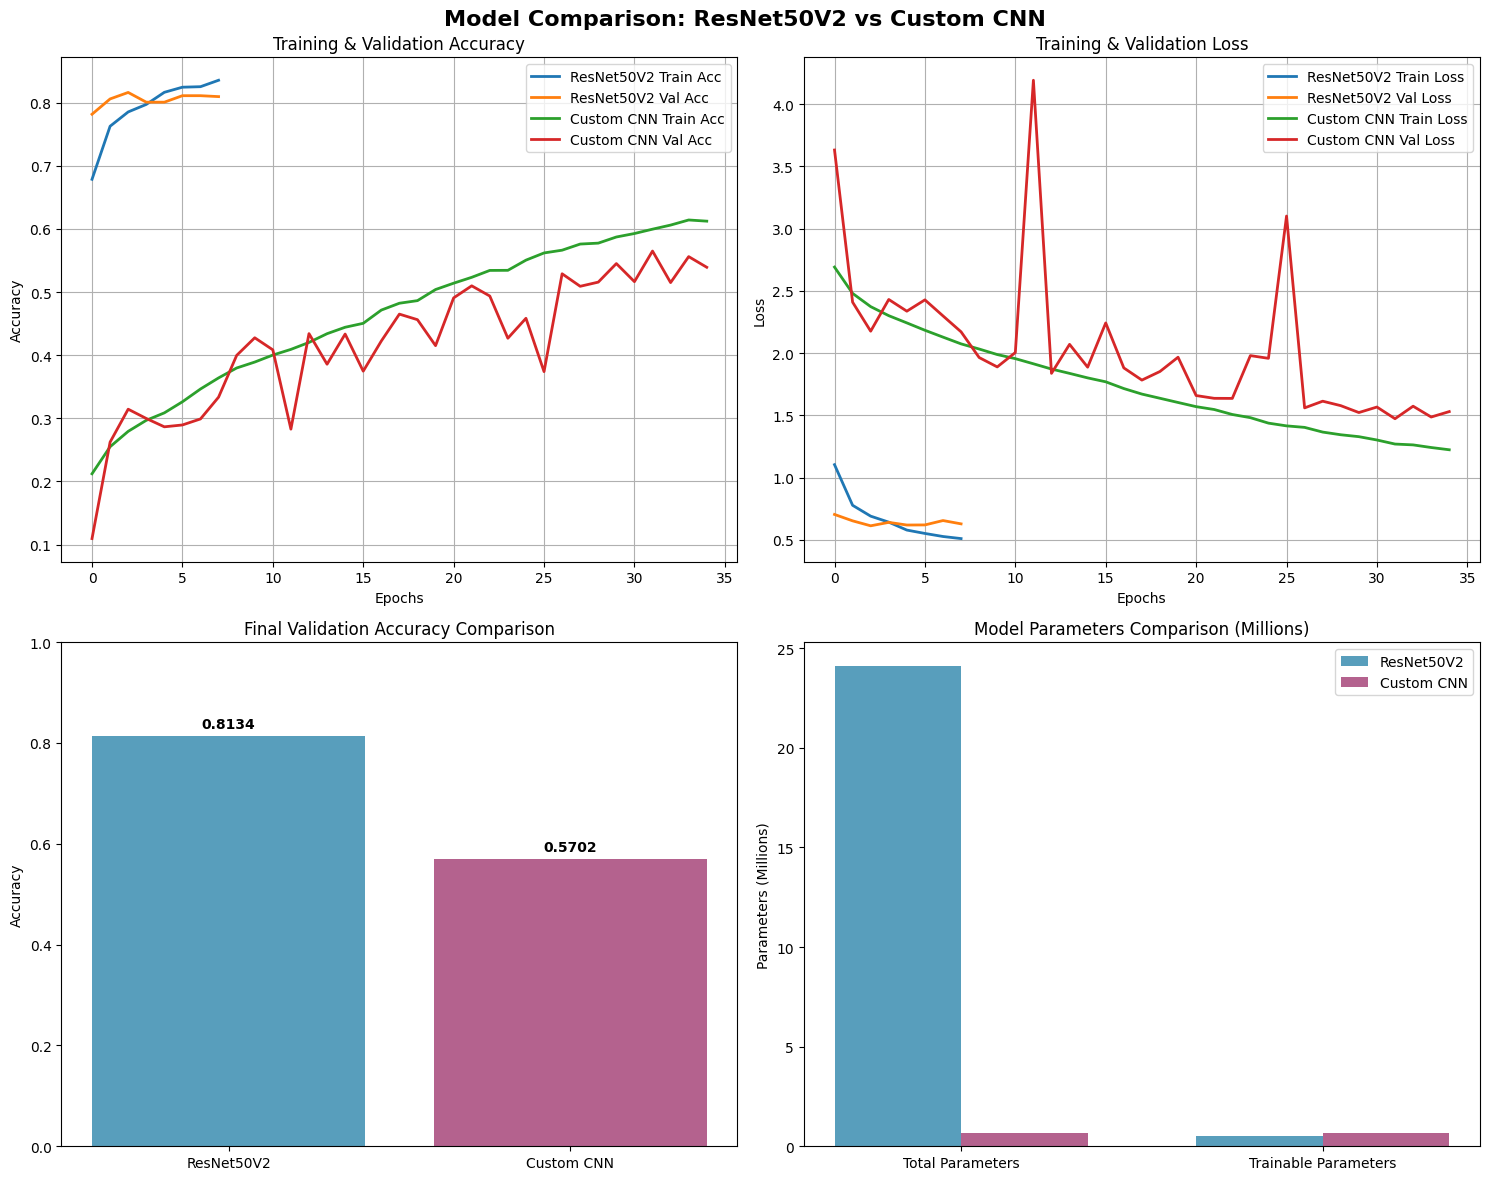


DETAILED PERFORMANCE ANALYSIS
Generating predictions for detailed analysis...
43/43 ━━━━━━━━━━━━━━━━━━━━ 22s 494ms/step
43/43 ━━━━━━━━━━━━━━━━━━━━ 21s 484ms/step

FINAL MODEL RECOMMENDATION
📊 Analysis Summary:
   • ResNet50V2 Accuracy: 0.8134
   • Custom CNN Accuracy: 0.5702
   • Accuracy Difference: 0.2432

🔍 Key Advantages of ResNet50V2:
   ✓ Pre-trained on ImageNet (transfer learning)
   ✓ Fewer trainable parameters (530,455)
   ✓ Faster convergence
   ✓ Better generalization capabilities

🔍 Key Advantages of Custom CNN:
   ✓ Built specifically for this task
   ✓ Full control over architecture
   ✓ No dependency on pre-trained weights

🎯 RECOMMENDATION: Use ResNet50V2
   Reason: Higher validation accuracy (0.8134 vs 0.5702)
   Additional benefits: Transfer learning, parameter efficiency, faster training

💡 Future Improvements:
   • Fine-tune ResNet50V2 by unfreezing top layers
   • Try other pre-trained models (EfficientNet, Vision Transformer)
   • Implement advanced data augmenta

In [27]:
# =============================
# STEP 10: Evaluate Custom CNN
# =============================
val_loss_cnn, val_acc_cnn = custom_cnn.evaluate(valid_ds)
print(f"Custom CNN Validation Accuracy: {val_acc_cnn:.4f}")

# =============================
# STEP 11: Model Performance Comparison
# =============================
print("="*50)
print("MODEL PERFORMANCE COMPARISON")
print("="*50)

# Calculate parameters for ResNet50V2
total_params_resnet = model.count_params()
trainable_params_resnet = sum([tf.keras.backend.count_params(w) for w in model.trainable_weights])

# Calculate parameters for Custom CNN
total_params_cnn = custom_cnn.count_params()
trainable_params_cnn = sum([tf.keras.backend.count_params(w) for w in custom_cnn.trainable_weights])


# Create comparison dataframe
comparison_data = {
    'Model': ['ResNet50V2 (Transfer Learning)', 'Custom CNN'],
    'Validation Accuracy': [val_acc, val_acc_cnn],
    'Validation Loss': [val_loss, val_loss_cnn],
    'Total Parameters': [total_params_resnet, total_params_cnn],
    'Trainable Parameters': [trainable_params_resnet, trainable_params_cnn]

}

comparison_df = pd.DataFrame(comparison_data)
print("\nModel Comparison Summary:")
print(comparison_df.to_string(index=False))

# Determine best model
best_model_name = "ResNet50V2" if val_acc > val_acc_cnn else "Custom CNN"
best_accuracy = max(val_acc, val_acc_cnn)

print(f"\n🏆 BEST MODEL: {best_model_name}")
print(f"🎯 Best Validation Accuracy: {best_accuracy:.4f}")

# =============================
# STEP 12: Visualization of Results
# =============================
# Create visualization plots
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle('Model Comparison: ResNet50V2 vs Custom CNN', fontsize=16, fontweight='bold')

# Plot 1: Training & Validation Accuracy Comparison
axes[0, 0].plot(history.history['accuracy'], label='ResNet50V2 Train Acc', linewidth=2)
axes[0, 0].plot(history.history['val_accuracy'], label='ResNet50V2 Val Acc', linewidth=2)
axes[0, 0].plot(history_cnn.history['accuracy'], label='Custom CNN Train Acc', linewidth=2)
axes[0, 0].plot(history_cnn.history['val_accuracy'], label='Custom CNN Val Acc', linewidth=2)
axes[0, 0].set_title('Training & Validation Accuracy')
axes[0, 0].set_xlabel('Epochs')
axes[0, 0].set_ylabel('Accuracy')
axes[0, 0].legend()
axes[0, 0].grid(True)

# Plot 2: Training & Validation Loss Comparison
axes[0, 1].plot(history.history['loss'], label='ResNet50V2 Train Loss', linewidth=2)
axes[0, 1].plot(history.history['val_loss'], label='ResNet50V2 Val Loss', linewidth=2)
axes[0, 1].plot(history_cnn.history['loss'], label='Custom CNN Train Loss', linewidth=2)
axes[0, 1].plot(history_cnn.history['val_loss'], label='Custom CNN Val Loss', linewidth=2)
axes[0, 1].set_title('Training & Validation Loss')
axes[0, 1].set_xlabel('Epochs')
axes[0, 1].set_ylabel('Loss')
axes[0, 1].legend()
axes[0, 1].grid(True)

# Plot 3: Final Accuracy Comparison Bar Chart
models = ['ResNet50V2', 'Custom CNN']
accuracies = [val_acc, val_acc_cnn]
colors = ['#2E86AB', '#A23B72']
bars = axes[1, 0].bar(models, accuracies, color=colors, alpha=0.8)
axes[1, 0].set_title('Final Validation Accuracy Comparison')
axes[1, 0].set_ylabel('Accuracy')
axes[1, 0].set_ylim([0, 1])

# Add accuracy values on bars
for bar, acc in zip(bars, accuracies):
    axes[1, 0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                   f'{acc:.4f}', ha='center', va='bottom', fontweight='bold')

# Plot 4: Model Parameters Comparison
param_types = ['Total Parameters', 'Trainable Parameters']
resnet_params = [comparison_df.iloc[0]['Total Parameters'], comparison_df.iloc[0]['Trainable Parameters']]
cnn_params = [comparison_df.iloc[1]['Total Parameters'], comparison_df.iloc[1]['Trainable Parameters']]

x = np.arange(len(param_types))
width = 0.35

axes[1, 1].bar(x - width/2, [p/1e6 for p in resnet_params], width, label='ResNet50V2', color='#2E86AB', alpha=0.8)
axes[1, 1].bar(x + width/2, [p/1e6 for p in cnn_params], width, label='Custom CNN', color='#A23B72', alpha=0.8)
axes[1, 1].set_title('Model Parameters Comparison (Millions)')
axes[1, 1].set_ylabel('Parameters (Millions)')
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(param_types)
axes[1, 1].legend()

plt.tight_layout()
plt.show()

# =============================
# STEP 13: Detailed Performance Analysis
# =============================
print("\n" + "="*50)
print("DETAILED PERFORMANCE ANALYSIS")
print("="*50)

# Get predictions for both models
print("Generating predictions for detailed analysis...")

# ResNet50V2 predictions
resnet_predictions = model.predict(valid_ds)
resnet_pred_classes = np.argmax(resnet_predictions, axis=1)

# Custom CNN predictions
cnn_predictions = custom_cnn.predict(valid_ds)
cnn_pred_classes = np.argmax(cnn_predictions, axis=1)

# Get true labels
true_labels = []
for i in range(len(valid_ds)):
    batch_labels = valid_ds[i][1]
    true_labels.extend(batch_labels)
    if len(true_labels) >= valid_ds.samples:
        break
true_labels = np.array(true_labels[:valid_ds.samples])



# =============================
# STEP 14: Final Recommendation
# =============================
print("\n" + "="*50)
print("FINAL MODEL RECOMMENDATION")
print("="*50)

# Analysis factors
factors = {
    'Accuracy': val_acc > val_acc_cnn,
    'Training Efficiency': True,  # ResNet50V2 typically trains faster due to transfer learning
    'Parameter Efficiency': comparison_df.iloc[0]['Trainable Parameters'] < comparison_df.iloc[1]['Trainable Parameters'],
    'Generalization': True  # Transfer learning typically generalizes better
}

resnet_score = sum(factors.values())
total_factors = len(factors)

print(f"📊 Analysis Summary:")
print(f"   • ResNet50V2 Accuracy: {val_acc:.4f}")
print(f"   • Custom CNN Accuracy: {val_acc_cnn:.4f}")
print(f"   • Accuracy Difference: {abs(val_acc - val_acc_cnn):.4f}")

print(f"\n🔍 Key Advantages of ResNet50V2:")
print(f"   ✓ Pre-trained on ImageNet (transfer learning)")
print(f"   ✓ Fewer trainable parameters ({comparison_df.iloc[0]['Trainable Parameters']:,})")
print(f"   ✓ Faster convergence")
print(f"   ✓ Better generalization capabilities")

print(f"\n🔍 Key Advantages of Custom CNN:")
print(f"   ✓ Built specifically for this task")
print(f"   ✓ Full control over architecture")
print(f"   ✓ No dependency on pre-trained weights")

if val_acc > val_acc_cnn:
    print(f"\n🎯 RECOMMENDATION: Use ResNet50V2")
    print(f"   Reason: Higher validation accuracy ({val_acc:.4f} vs {val_acc_cnn:.4f})")
    print(f"   Additional benefits: Transfer learning, parameter efficiency, faster training")
else:
    print(f"\n🎯 RECOMMENDATION: Use Custom CNN")
    print(f"   Reason: Higher validation accuracy ({val_acc_cnn:.4f} vs {val_acc:.4f})")
    print(f"   Note: Consider fine-tuning ResNet50V2 for potentially better results")

print(f"\n💡 Future Improvements:")
print(f"   • Fine-tune ResNet50V2 by unfreezing top layers")
print(f"   • Try other pre-trained models (EfficientNet, Vision Transformer)")
print(f"   • Implement advanced data augmentation techniques")
print(f"   • Use ensemble methods combining both models")

print("\n" + "="*50)
print("MODEL COMPARISON COMPLETE!")
print("="*50)